# Ajustes NOGSE libres con lóbulos trapezoidales ($b$ exacto de la forma de onda)

Notebook para el fantoma de agua (set v2.00, $128\times128$). Lee `master.long.parquet`, ajusta solo $D_0$ (con $M_0=1$) a cada señal Hahn y CPMG y al contraste CPMG − Hahn, y guarda figuras y tablas en `signal_analysis/results/trapezoidal_lobes/sub-<SUB>/`.

Modelo: **lóbulos trapezoidales**, el $b$ exacto de la forma de onda que juega la secuencia (rampas de 1.2 ms dentro de cada período), calculado con `nogse_trapezoid_b_per_g2` de `src/fitting/b_from_g.py`. Es el ajuste de la versión anterior de este notebook (commit `973d1ee`), escrito de forma análoga a `nogse_fits_rectangular_lobes.ipynb`; los dos escriben las mismas figuras y tablas en carpetas distintas para compararlas.

## Qué datos entran y de dónde sale cada parámetro

Cada fila de `master.long.parquet` es la señal de un volumen en un ROI. Este notebook usa solo `roi = water`, `stat = avg` y las series CPMG y Hahn (la serie b0 PA es solo para TOPUP).

| Columna | Símbolo | Qué es | De dónde viene |
|---|---|---|---|
| `value` | $S(G)$ | media de la señal en el ROI de agua (máscara manual) del volumen | `signal_extraction` sobre el NIfTI (`raw` o `den_gr`) |
| `S0`, `value_norm` | $S_0$, $M = S/S_0$ | $S_0$ es la media de los dos volúmenes b0 de la **misma** serie; $M(G=0)=1$ por construcción | ingest de `signal_analysis` |
| `TN` | $T$ | duración total del bloque NOGSE, $T_{NOGSE}$ (ms); también `td_ms` | planilla `sequence_parameters_phantoms.xlsx` = protocolo YAML del `.seq` |
| `N` | $N$ | número de períodos de la modulación (aquí $N=2$) | ídem |
| `x` | $x$ | período CPMG (ms): $x=T/N$ en la serie CPMG; $x = 5$ ms (fijo) en la serie Hahn | ídem |
| `y` | $y$ | período Hahn, $y = T-(N-1)x$ (ms) | ídem |
| `ramp_time_ms` | $t_r$ | tiempo de rampa de cada trapecio, 1.2 ms | ídem |
| `bvalue` | $b$ | b-value del `.bval` (s/mm²): traza de la matriz $b$ **exacta** de los trapecios jugados, calculada por el generador de la secuencia | `.bval` de BIDS |
| `g` | $G$ | amplitud del gradiente NOGSE (mT/m): 0, 7, …, 70 equiespaciado | ingest: $G=\sqrt{b/k_{trap}(T,N,x,t_r)}$, que invierte exactamente el `.bval` |
| `direction` | — | eje del gradiente en el escáner: 1 = $x$, 2 = $y$, 3 = $z$ (bvec $[1,0,0]$, $[0,1,0]$, $[0,0,1]$) | `.bvec` |

**Forma de onda efectiva** (signo invertido por los pulsos π virtuales, que en esta secuencia Pulseq se implementan con la polaridad del gradiente): para $N=2$ son cuatro lóbulos de amplitud $G$ y signos $+,-,-,+$ con duraciones $x/2,\ x/2,\ y/2,\ y/2$. El vector de onda es $q(t)=\gamma\int_0^t g(t')\,dt'$ y vuelve a cero al final del bloque. Para difusión libre con coeficiente $D_0$,

$$M = \frac{S}{S_0} = M_0\,e^{-b\,D_0},\qquad b=\int_0^{T} q(t)^2\,dt = k(T,N,x)\,G^2 .$$

Todo depende de $G^2$: el factor $k$ (s/mm² por (mT/m)²) solo depende de la temporización. **La única diferencia entre los dos notebooks es cómo se calcula $k$** (lóbulos rectangulares o trapezoidales); el resto de las celdas es idéntico.

**Ajuste.** Para cada curva (tipo, $T$, dirección) se ajusta un único parámetro, $D_0$, con $M_0=1$ fijo (porque $M(0)=1$), minimizando el error cuadrático medio en escala lineal sobre los 11 puntos ($G=0,\dots,70$ mT/m). Se optimiza $\ln D_0$ en $[10^{-4},10^{-2}]$ mm²/s para mantener $D_0>0$.

**Contraste.** $\Delta M(G) = M_{CPMG}(G) - M_{Hahn}(G) = e^{-k_{CPMG}G^2D_0} - e^{-k_{Hahn}G^2D_0}$, con los puntos emparejados por $T$, dirección y `b_step` (mismo $G$). Se ajusta también un solo $D_0$ por ($T$, dirección). Con un Hahn ideal ($x\to0$) y lóbulos rectangulares, $k_{CPMG}/k_{Hahn}=1/N^2=1/4$ para todo $T$ y el pico del contraste vale $0.4725$ siempre; con $x_{Hahn}=5$ ms fijo el cociente cambia con $T$ y el pico también.

**Advertencia.** Con $S/S_0 \lesssim 0.2$ los puntos quedan sobre el piso de ruido de la magnitud (≈ 0.11 en este fantoma) y el modelo exponencial no lo describe; los $D_0$ de $T$ largos están sesgados por eso.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from fitting.b_from_g import nogse_trapezoid_b_per_g2
from models.model_fitting import _GYRO

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

Por defecto se usa la rama denoised + Gibbs-removal (`den_gr--manual`). `SUB` selecciona explícitamente `PHANTOM-1` o `PHANTOM-2`; los datos y las salidas nunca se mezclan entre sujetos. Cambiar solo `ANALYSIS_TAG` permite repetir exactamente el análisis con `raw--manual`. `MODEL_NAME` define la carpeta de salida; el otro notebook escribe los mismos archivos en `OTHER_MODEL_NAME`.

In [2]:
MODEL_NAME = 'trapezoidal_lobes'
OTHER_MODEL_NAME = 'rectangular_lobes'
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB = 'PHANTOM-2'  # alternativa: 'PHANTOM-1'
SESSION_ID = 'T0'
ROI = 'water'
STAT = 'avg'
D0_BOUNDS_MM2_S = (1e-4, 1e-2)
MM2_S_TO_M2_MS = 1e-9  # D0 de model_fitting en m^2/ms

MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
OUTPUT_ROOT = REPO_ROOT / 'results' / MODEL_NAME / f'sub-{SUB}' / f'ses-{SESSION_ID}'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIRECTION_DIR = OUTPUT_ROOT / 'contrasts_by_direction'
CONTRAST_TIME_DIR = OUTPUT_ROOT / 'contrasts_by_time'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIRECTION_DIR, CONTRAST_TIME_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

master = pd.read_parquet(MASTER_PATH)
available_subjects = sorted(master['subj'].astype(str).unique())
if SUB not in available_subjects:
    raise ValueError(f'SUB={SUB!r} no está en el master. Disponibles: {available_subjects}')
data = master.loc[(master['subj'].astype(str) == SUB) &
                  (master['session_id'].astype(str) == SESSION_ID) &
                  (master['stat'].astype(str) == STAT) &
                  (master['roi'].astype(str) == ROI) &
                  (master['type'].astype(str).str.upper().isin(['CPMG', 'HAHN']))].copy()
data['type'] = data['type'].astype(str).str.upper()
data['direction'] = data['direction'].astype(str)
for column in ['td_ms', 'TN', 'N', 'x', 'ramp_time_ms', 'g', 'bvalue', 'b_step', 'value_norm']:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.dropna(subset=['td_ms', 'TN', 'N', 'x', 'ramp_time_ms', 'g', 'bvalue', 'b_step', 'value_norm'])
if not np.allclose(data['TN'], data['td_ms']):
    raise ValueError('TN y td_ms no coinciden: revisar la tabla de parámetros.')

print('Modelo:', MODEL_NAME)
print('Sujeto:', SUB)
print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['type', 'td_ms', 'direction']).size().rename('n').reset_index())

Modelo: trapezoidal_lobes
Sujeto: PHANTOM-2
Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/trapezoidal_lobes/sub-PHANTOM-2


,type,td_ms,direction,n
0,CPMG,30.0,1,11
1,CPMG,30.0,2,11
2,CPMG,30.0,3,11
3,CPMG,40.0,1,11
4,CPMG,40.0,2,11
5,CPMG,40.0,3,11
6,CPMG,50.0,1,11
7,CPMG,50.0,2,11
8,CPMG,50.0,3,11
9,CPMG,65.0,1,11


## Modelo: lóbulos trapezoidales ($b$ exacto)

La secuencia (`sbb_nogse_grad.py`, desde v1.06) juega cada lóbulo de duración $d\in\{x/2,\,y/2\}$ como un trapecio que ocupa exactamente su período: rampa lineal de $0$ a $\pm G$ en $t_r$, meseta de duración $d-2t_r$ y rampa de vuelta a $0$ en $t_r$ ($t_r$ = 1.2 ms). La forma de onda efectiva es lineal a trozos,

$$g(t) = g_0 + a\,(t-t_0)\quad\text{en cada tramo (rampa o meseta)},$$

así que $q(t)=\gamma\int g$ es cuadrática en cada tramo y $q^2$ es un polinomio de grado 4 que se integra exactamente. Sumando los tramos de los cuatro lóbulos ($+,-,-,+$ para $N=2$),

$$k_{trap}(T,N,x,t_r) = \frac{1}{G^2}\int_0^T q(t)^2\,dt$$

en s/mm² por (mT/m)² (`nogse_trapezoid_b_per_g2(N, TN_ms, x_ms, ramp_time_ms, gamma)`). Para $t_r\to0$ se recupera $k_{rect}=\gamma^2[(N-1)x^3+y^3]/12$. Con rampas, cada lóbulo pierde área ($A_{lóbulo}=G(d-t_r)$ en vez de $Gd$) y $k_{trap}<k_{rect}$; la reducción es mayor cuanto más cortos son los lóbulos respecto de $t_r$ (CPMG con $T$ corto: $x/2=7.5$ ms, $k_{trap}/k_{rect}=0.76$).

El modelo es

$$M = M_0\,e^{-k_{trap}(T,N,x,t_r)\,G^2\,D_0},$$

con $D_0$ en mm²/s y $k_{trap}G^2$ = el `bvalue` de la tabla (la última sección lo verifica). Se usa el mismo $\gamma$ = `_GYRO` = 267.522 rad ms⁻¹ mT⁻¹ que en el notebook rectangular, para que la única diferencia sea la forma de los lóbulos; el generador usa $\gamma/2\pi$ = 42.576 MHz/T, una diferencia relativa de $3\times10^{-5}$ en $b$.

Para el contraste se resta el modelo con $x=T/N$ menos el modelo con $x=5$ ms, cada uno con su $k_{trap}$.

In [3]:
def k_model(tn_ms, n_value, x_ms, ramp_ms):
    # s/mm^2 per (mT/m)^2 of the played trapezoidal waveform (exact b / G^2)
    return nogse_trapezoid_b_per_g2(N=n_value, TN_ms=tn_ms, x_ms=x_ms, ramp_time_ms=ramp_ms, gamma=_GYRO)


def signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    return np.exp(-k_model(tn_ms, n_value, x_ms, ramp_ms) * np.asarray(g_mT_m, float)**2 * d0_mm2_s)

Funciones comunes a los dos notebooks: el modelo de contraste, el ajuste de un parámetro y la lectura de $T$, $N$, $x$, $t_r$ de cada curva.

In [4]:
def contrast_model(tn_ms, g_mT_m, n_value, x_cpmg_ms, x_hahn_ms, ramp_cpmg_ms, ramp_hahn_ms, d0_mm2_s):
    # Each series with its own ramp (since 2026-10-26 the Hahn series may have 2x the CPMG ramps).
    return (signal_model(tn_ms, g_mT_m, n_value, x_cpmg_ms, ramp_cpmg_ms, d0_mm2_s)
            - signal_model(tn_ms, g_mT_m, n_value, x_hahn_ms, ramp_hahn_ms, d0_mm2_s))


def fit_one_parameter(y, model):
    y = np.asarray(y, float)
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_MM2_S)

    def loss(log_d0):
        prediction = np.asarray(model(np.exp(log_d0)), float)
        return np.mean((y[valid] - prediction[valid]) ** 2)

    result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
    d0 = float(np.exp(result.x))
    prediction = np.asarray(model(d0), float)
    residual = y[valid] - prediction[valid]
    return {
        'D0_mm2_s': d0,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'n_points': int(valid.sum()),
        'ok': bool(result.success),
    }


def timing(curve):
    row = curve.iloc[0]
    return float(row['TN']), float(row['N']), float(row['x']), float(row['ramp_time_ms'])


def d0_label(d0):
    return f'$D_0$={d0 * 1e3:.3f} × 10$^{{-3}}$ mm²/s'


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')

## Hahn y CPMG: una figura por medición

Cada figura contiene las tres direcciones y su propio $D_0$ ajustado. Se generan ocho figuras: Hahn y CPMG para cada uno de los cuatro tiempos.

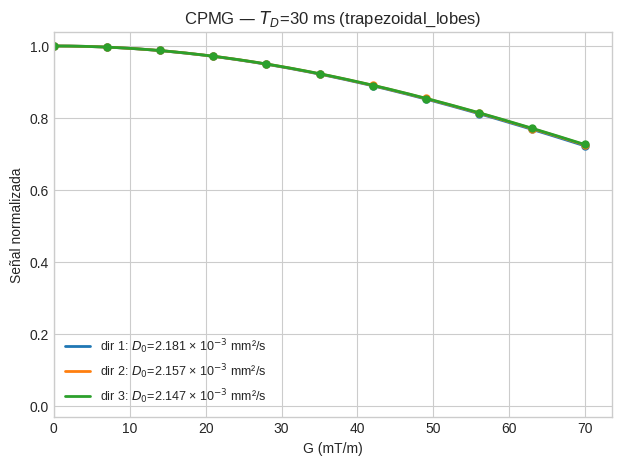

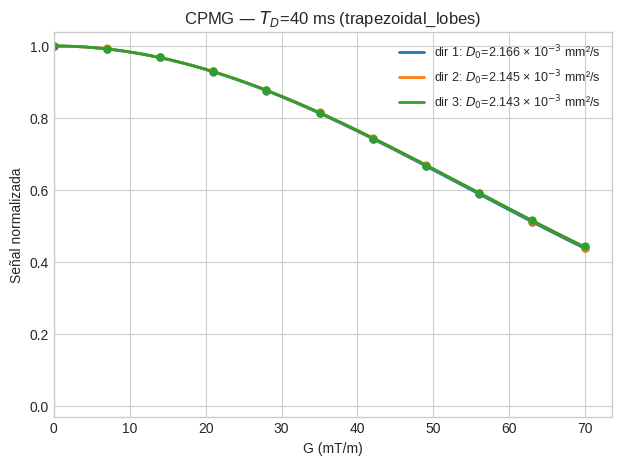

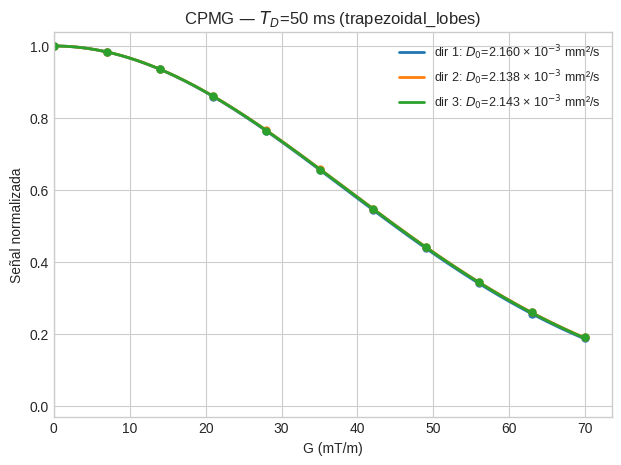

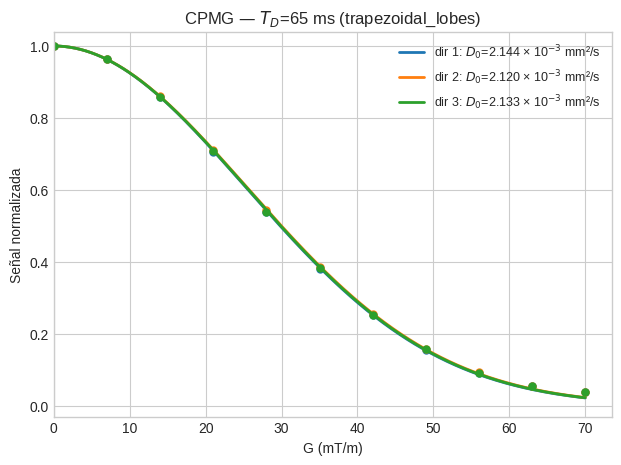

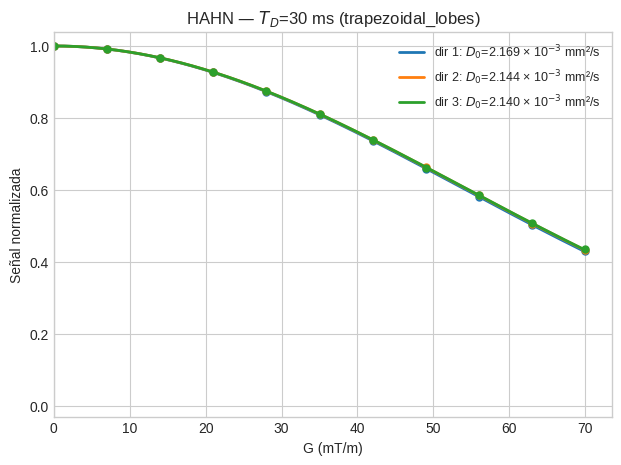

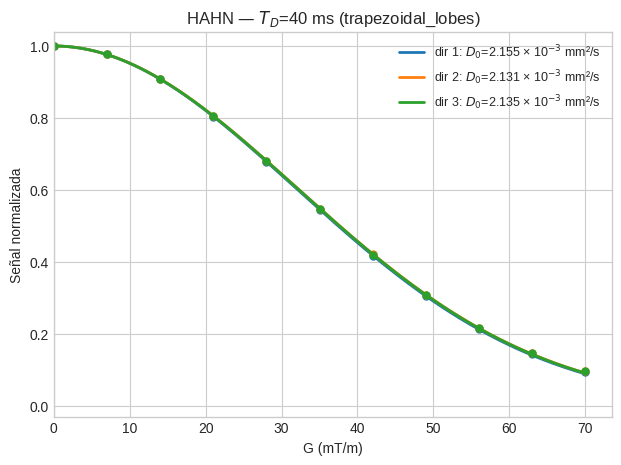

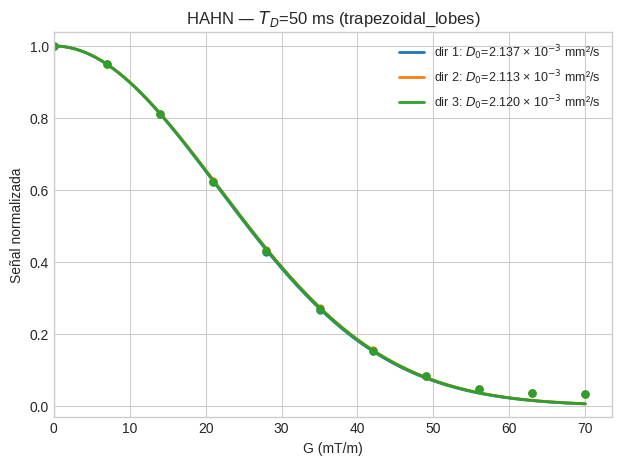

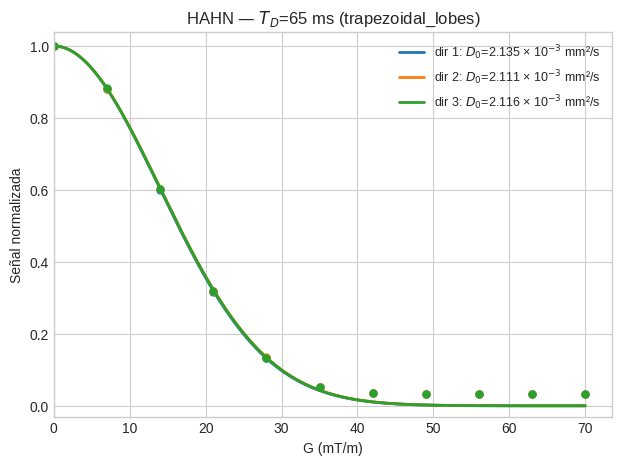

,model,analysis_tag,subj,roi,type,td_ms,direction,N,x_ms,k_s_mm2_per_mT2_m2,D0_mm2_s,rmse,n_points,ok
0,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,30.0,1,2.0,15.0,0.030470,0.002181,0.000536,11,True
1,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,30.0,2,2.0,15.0,0.030470,0.002157,0.000441,11,True
2,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,30.0,3,2.0,15.0,0.030470,0.002147,0.000940,11,True
3,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,40.0,1,2.0,20.0,0.078036,0.002166,0.000550,11,True
4,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,40.0,2,2.0,20.0,0.078036,0.002145,0.000801,11,True
5,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,40.0,3,2.0,20.0,0.078036,0.002143,0.001390,11,True
6,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,50.0,1,2.0,25.0,0.159240,0.002160,0.000958,11,True
7,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,50.0,2,2.0,25.0,0.159240,0.002138,0.000670,11,True
8,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,50.0,3,2.0,25.0,0.159240,0.002143,0.001755,11,True
9,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,CPMG,65.0,1,2.0,32.5,0.363684,0.002144,0.006379,11,True


In [5]:
direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
signal_fit_rows = []

for (sequence_type, td_ms), measurement in data.groupby(['type', 'td_ms'], sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in measurement.groupby('direction', sort=True):
        curve = curve.sort_values('g')
        tn_ms, n_value, x_ms, ramp_ms = timing(curve)
        g = curve['g'].to_numpy(float)
        y = curve['value_norm'].to_numpy(float)
        fit = fit_one_parameter(y, lambda d0: signal_model(tn_ms, g, n_value, x_ms, ramp_ms, d0))
        signal_fit_rows.append({
            'model': MODEL_NAME, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'roi': ROI, 'type': sequence_type,
            'td_ms': td_ms, 'direction': direction, 'N': n_value, 'x_ms': x_ms,
            'k_s_mm2_per_mT2_m2': k_model(tn_ms, n_value, x_ms, ramp_ms), **fit
        })
        color = direction_colors.get(direction)
        ax.plot(g, y, 'o', color=color, ms=5)
        g_fine = np.linspace(0, g.max(), 400)
        ax.plot(g_fine, signal_model(tn_ms, g_fine, n_value, x_ms, ramp_ms, fit['D0_mm2_s']),
                color=color, lw=2, label=f'dir {direction}: {d0_label(fit["D0_mm2_s"])}')
    ax.set(title=f'{sequence_type} — $T_D$={td_ms:g} ms ({MODEL_NAME})', xlabel='G (mT/m)',
           ylabel='Señal normalizada', xlim=(0, None), ylim=(-0.03, 1.04))
    ax.legend(fontsize=9)
    save_figure(fig, SIGNAL_DIR, f'signal_{sequence_type}_Td-{td_ms:g}ms')
    plt.show()

signal_fits = pd.DataFrame(signal_fit_rows).sort_values(['type', 'td_ms', 'direction'])
signal_fits.to_csv(TABLE_DIR / 'signal_fits.csv', index=False)
display(signal_fits)

## Construcción y ajuste del contraste CPMG − Hahn

Las curvas se emparejan estrictamente por tiempo, dirección y `b_step`. También se verifica que $G$, $N$, $T$ y $t_r$ coincidan. Cada combinación tiempo-dirección tiene un único ajuste de $D_0$, reutilizado en las dos galerías siguientes.

In [6]:
keys = ['td_ms', 'direction', 'b_step']
paired = ['g', 'bvalue', 'TN', 'N', 'x', 'ramp_time_ms', 'value_norm']
cpmg = data.loc[data['type'].eq('CPMG'), keys + paired].rename(columns={c: f'{c}_cpmg' for c in paired})
hahn = data.loc[data['type'].eq('HAHN'), keys + paired].rename(columns={c: f'{c}_hahn' for c in paired})
contrast = cpmg.merge(hahn, on=keys, how='inner', validate='one_to_one')
for column in ['g', 'TN', 'N']:  # the ramps may differ (Hahn 2 x CPMG, 2026-10-26)
    if not np.allclose(contrast[f'{column}_cpmg'], contrast[f'{column}_hahn'], rtol=1e-6, atol=1e-6):
        raise ValueError(f'CPMG y Hahn no tienen el mismo {column} para todos los puntos emparejados.')
contrast['g'] = contrast['g_cpmg']
contrast['value_contrast'] = contrast['value_norm_cpmg'] - contrast['value_norm_hahn']


def contrast_timing(curve):
    row = curve.iloc[0]
    return (float(row['TN_cpmg']), float(row['N_cpmg']), float(row['x_cpmg']), float(row['x_hahn']),
            float(row['ramp_time_ms_cpmg']), float(row['ramp_time_ms_hahn']))


contrast_fit_rows = []
for (td_ms, direction), curve in contrast.groupby(['td_ms', 'direction'], sort=True):
    curve = curve.sort_values('g')
    tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn = contrast_timing(curve)
    g = curve['g'].to_numpy(float)
    y = curve['value_contrast'].to_numpy(float)
    fit = fit_one_parameter(y, lambda d0: contrast_model(tn_ms, g, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0))
    contrast_fit_rows.append({
        'model': MODEL_NAME, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'roi': ROI, 'td_ms': td_ms, 'direction': direction,
        'N': n_value, 'x_cpmg_ms': x_cpmg, 'x_hahn_ms': x_hahn,
        'k_ratio_cpmg_over_hahn': k_model(tn_ms, n_value, x_cpmg, ramp_cpmg) / k_model(tn_ms, n_value, x_hahn, ramp_hahn), **fit
    })

contrast_fits = pd.DataFrame(contrast_fit_rows).sort_values(['td_ms', 'direction'])
contrast_fits.to_csv(TABLE_DIR / 'contrast_fits.csv', index=False)
display(contrast_fits)

,model,analysis_tag,subj,roi,td_ms,direction,N,x_cpmg_ms,x_hahn_ms,k_ratio_cpmg_over_hahn,D0_mm2_s,rmse,n_points,ok
0,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,30.0,1,2.0,15.0,5.0,0.381578,0.002154,0.000354,11,True
1,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,30.0,2,2.0,15.0,5.0,0.381578,0.002130,0.000420,11,True
2,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,30.0,3,2.0,15.0,5.0,0.381578,0.002131,0.000300,11,True
3,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,40.0,1,2.0,20.0,5.0,0.340171,0.002184,0.002170,11,True
4,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,40.0,2,2.0,20.0,5.0,0.340171,0.002167,0.002418,11,True
5,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,40.0,3,2.0,20.0,5.0,0.340171,0.002144,0.001774,11,True
6,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,50.0,1,2.0,25.0,5.0,0.318541,0.002282,0.005625,11,True
7,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,50.0,2,2.0,25.0,5.0,0.318541,0.002261,0.005671,11,True
8,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,50.0,3,2.0,25.0,5.0,0.318541,0.002254,0.005946,11,True
9,trapezoidal_lobes,den_gr--manual,PHANTOM-2,water,65.0,1,2.0,32.5,5.0,0.300388,0.002337,0.008388,11,True


## Contrastes: cuatro tiempos para cada dirección

Cada figura tiene exactamente cuatro curvas, una para cada tiempo disponible.

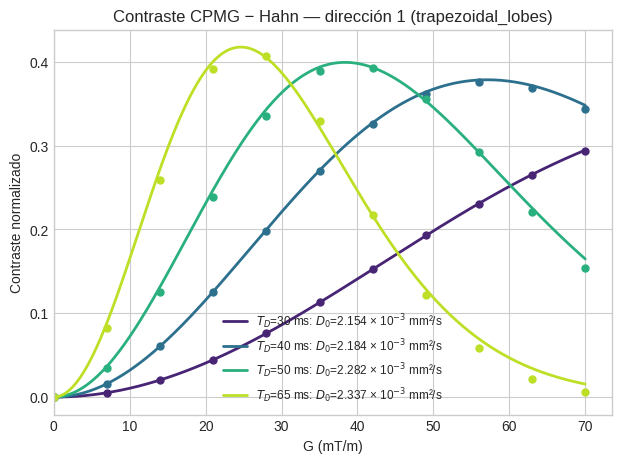

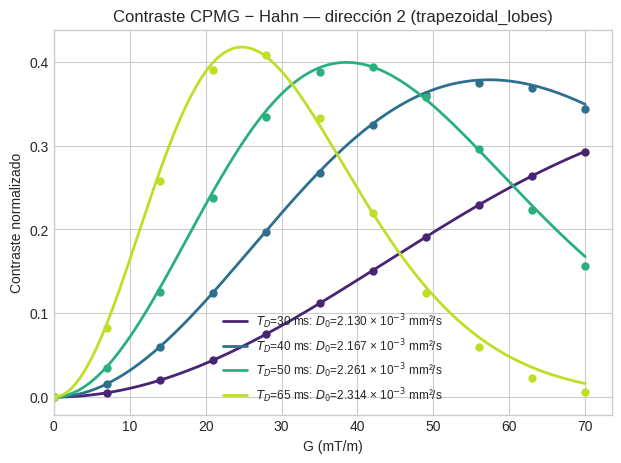

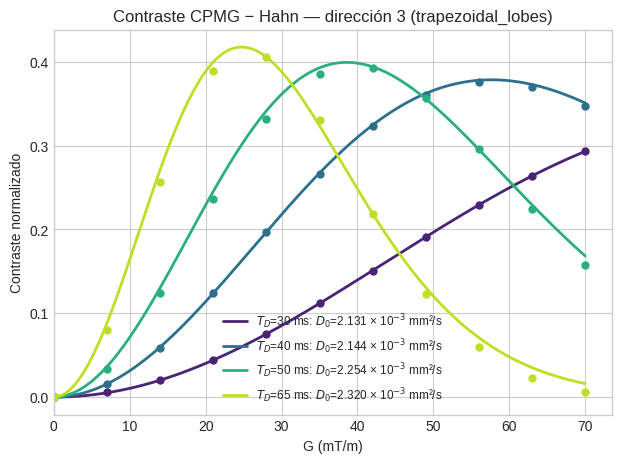

In [7]:
time_colors = dict(zip(sorted(contrast['td_ms'].unique()), plt.cm.viridis(np.linspace(0.1, 0.9, contrast['td_ms'].nunique()))))


def plot_contrast_curve(ax, curve, d0, color, label):
    curve = curve.sort_values('g')
    tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn = contrast_timing(curve)
    ax.plot(curve['g'], curve['value_contrast'], 'o', color=color, ms=5)
    g_fine = np.linspace(0, curve['g'].max(), 400)
    ax.plot(g_fine, contrast_model(tn_ms, g_fine, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0), color=color, lw=2,
            label=f'{label}: {d0_label(d0)}')


def contrast_d0(td_ms, direction):
    return contrast_fits.loc[contrast_fits['td_ms'].eq(td_ms) & contrast_fits['direction'].eq(direction), 'D0_mm2_s'].iloc[0]


for direction, panel in contrast.groupby('direction', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for td_ms, curve in panel.groupby('td_ms', sort=True):
        plot_contrast_curve(ax, curve, contrast_d0(td_ms, direction), time_colors[td_ms], f'$T_D$={td_ms:g} ms')
    ax.set(title=f'Contraste CPMG − Hahn — dirección {direction} ({MODEL_NAME})', xlabel='G (mT/m)',
           ylabel='Contraste normalizado', xlim=(0, None))
    ax.legend(fontsize=8.5)
    save_figure(fig, CONTRAST_DIRECTION_DIR, f'contrast_direction-{direction}')
    plt.show()

## Contrastes: mismo tiempo y distinta dirección

Esta galería muestra directamente cuánto coinciden (o no) las tres direcciones a cada tiempo.

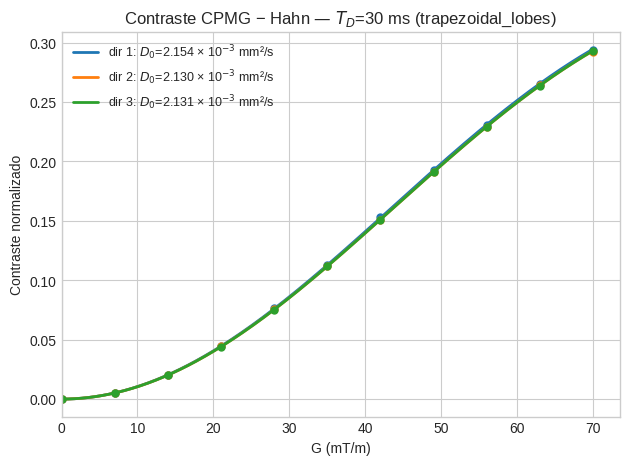

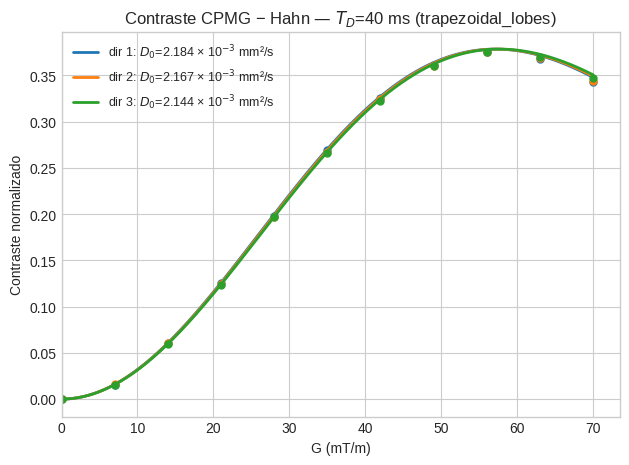

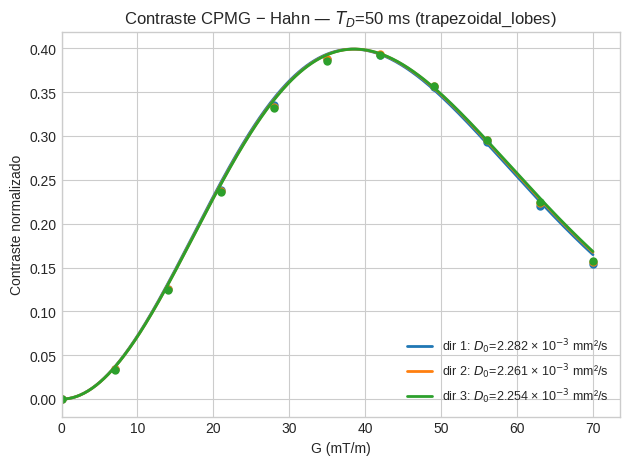

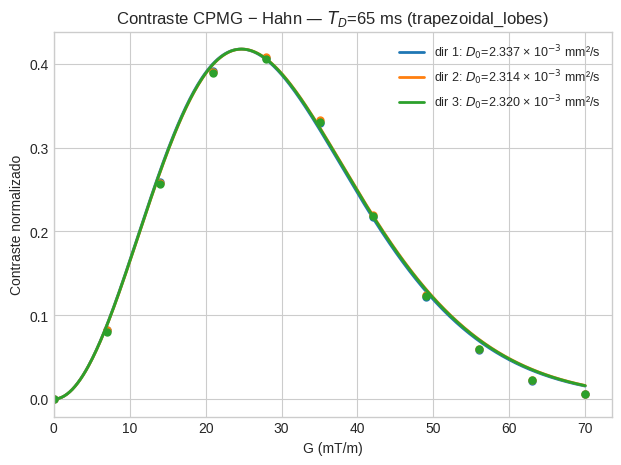

In [8]:
for td_ms, panel in contrast.groupby('td_ms', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in panel.groupby('direction', sort=True):
        plot_contrast_curve(ax, curve, contrast_d0(td_ms, direction), direction_colors.get(direction), f'dir {direction}')
    ax.set(title=f'Contraste CPMG − Hahn — $T_D$={td_ms:g} ms ({MODEL_NAME})', xlabel='G (mT/m)',
           ylabel='Contraste normalizado', xlim=(0, None))
    ax.legend(fontsize=9)
    save_figure(fig, CONTRAST_TIME_DIR, f'contrast_Td-{td_ms:g}ms')
    plt.show()

## Diagnóstico de las diferencias entre direcciones

`max_direction_range` es la máxima separación absoluta entre las tres curvas medidas a un mismo $G$. `rms_direction_spread` resume la dispersión respecto de la media direccional. Estos valores se calculan antes del ajuste y son iguales en los dos notebooks. `D0_cv_percent` cuantifica la variación de los $D_0$ ajustados entre direcciones.

In [9]:
qc_rows = []
for (sequence_type, td_ms), panel in data.groupby(['type', 'td_ms'], sort=True):
    wide = panel.pivot(index='b_step', columns='direction', values='value_norm')
    point_ranges = wide.max(axis=1) - wide.min(axis=1)
    point_spread = wide.sub(wide.mean(axis=1), axis=0)
    fitted = signal_fits.loc[(signal_fits['type'].eq(sequence_type)) & signal_fits['td_ms'].eq(td_ms), 'D0_mm2_s']
    qc_rows.append({
        'model': MODEL_NAME, 'subj': SUB, 'type': sequence_type, 'td_ms': td_ms,
        'max_direction_range': float(point_ranges.max()),
        'rms_direction_spread': float(np.sqrt(np.nanmean(point_spread.to_numpy()**2))),
        'D0_mean_mm2_s': float(fitted.mean()),
        'D0_cv_percent': float(100 * fitted.std(ddof=1) / fitted.mean()),
    })

direction_qc = pd.DataFrame(qc_rows)
direction_qc.to_csv(TABLE_DIR / 'direction_qc.csv', index=False)
display(direction_qc)

,model,subj,type,td_ms,max_direction_range,rms_direction_spread,D0_mean_mm2_s,D0_cv_percent
0,trapezoidal_lobes,PHANTOM-2,CPMG,30.0,0.004587,0.000908,0.002161,0.802214
1,trapezoidal_lobes,PHANTOM-2,CPMG,40.0,0.005996,0.001272,0.002151,0.595147
2,trapezoidal_lobes,PHANTOM-2,CPMG,50.0,0.004132,0.001286,0.002147,0.533228
3,trapezoidal_lobes,PHANTOM-2,CPMG,65.0,0.004448,0.001114,0.002132,0.563919
4,trapezoidal_lobes,PHANTOM-2,HAHN,30.0,0.005298,0.001345,0.002151,0.720848
5,trapezoidal_lobes,PHANTOM-2,HAHN,40.0,0.004610,0.001273,0.002140,0.606934
6,trapezoidal_lobes,PHANTOM-2,HAHN,50.0,0.004593,0.001042,0.002123,0.592022
7,trapezoidal_lobes,PHANTOM-2,HAHN,65.0,0.004329,0.000823,0.002121,0.577222


## Comprobación: $k$ del modelo frente al `bvalue` de la tabla

`k_model` es el $k$ de este notebook; `k_from_bvalue` = mediana de `bvalue`/$G^2$ (el $b$ exacto de la secuencia). En el notebook trapezoidal el cociente es 1 (salvo $3\times10^{-5}$ por $\gamma$); en el rectangular es el factor de rampas $k_{trap}/k_{rect}<1$, que es exactamente cuánto menor sale $D_0$ respecto del ajuste trapezoidal.

In [10]:
k_rows = []
for (sequence_type, td_ms), curve in data.groupby(['type', 'td_ms'], sort=True):
    tn_ms, n_value, x_ms, ramp_ms = timing(curve)
    positive = curve['g'] > 0
    k_table = float(np.median(curve.loc[positive, 'bvalue'] / curve.loc[positive, 'g']**2))
    k_rows.append({'model': MODEL_NAME, 'subj': SUB, 'type': sequence_type, 'td_ms': td_ms, 'x_ms': x_ms, 'ramp_ms': ramp_ms,
                   'k_model': k_model(tn_ms, n_value, x_ms, ramp_ms), 'k_from_bvalue': k_table,
                   'k_from_bvalue_over_k_model': k_table / k_model(tn_ms, n_value, x_ms, ramp_ms)})
k_check = pd.DataFrame(k_rows)
k_check.to_csv(TABLE_DIR / 'k_check.csv', index=False)
display(k_check)

,model,subj,type,td_ms,x_ms,ramp_ms,k_model,k_from_bvalue,k_from_bvalue_over_k_model
0,trapezoidal_lobes,PHANTOM-2,CPMG,30.0,15.0,1.2,0.030470,0.030468,0.999931
1,trapezoidal_lobes,PHANTOM-2,CPMG,40.0,20.0,1.2,0.078036,0.078031,0.999931
2,trapezoidal_lobes,PHANTOM-2,CPMG,50.0,25.0,1.2,0.159240,0.159229,0.999931
3,trapezoidal_lobes,PHANTOM-2,CPMG,65.0,32.5,1.2,0.363684,0.363659,0.999931
4,trapezoidal_lobes,PHANTOM-2,HAHN,30.0,5.0,1.2,0.079852,0.079846,0.999931
5,trapezoidal_lobes,PHANTOM-2,HAHN,40.0,5.0,1.2,0.229403,0.229387,0.999931
6,trapezoidal_lobes,PHANTOM-2,HAHN,50.0,5.0,1.2,0.499904,0.499869,0.999931
7,trapezoidal_lobes,PHANTOM-2,HAHN,65.0,5.0,1.2,1.210715,1.210631,0.999931


## Comparación con el otro notebook

Si el otro notebook ya se ejecutó, se comparan los $D_0$ de las señales y del contraste curva por curva (`D0_this / D0_other`).

In [11]:
other_tables = REPO_ROOT / 'results' / OTHER_MODEL_NAME / f'sub-{SUB}' / 'tables'
keys = {'signal_fits.csv': ['type', 'td_ms', 'direction'], 'contrast_fits.csv': ['td_ms', 'direction']}
for name, on in keys.items():
    other_path = other_tables / name
    if not other_path.exists():
        print(f'{other_path} no existe todavía: ejecutar el notebook {OTHER_MODEL_NAME}.')
        continue
    this = pd.read_csv(TABLE_DIR / name, dtype={'direction': str})
    other = pd.read_csv(other_path, dtype={'direction': str})
    merged = this[on + ['D0_mm2_s']].merge(other[on + ['D0_mm2_s']], on=on, suffixes=(f'_{MODEL_NAME}', f'_{OTHER_MODEL_NAME}'))
    merged['ratio_this_over_other'] = merged[f'D0_mm2_s_{MODEL_NAME}'] / merged[f'D0_mm2_s_{OTHER_MODEL_NAME}']
    print(name)
    display(merged)
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)

signal_fits.csv


,type,td_ms,direction,D0_mm2_s_trapezoidal_lobes,D0_mm2_s_rectangular_lobes,ratio_this_over_other
0,CPMG,30.0,1,0.002181,0.001650,1.321219
1,CPMG,30.0,2,0.002157,0.001632,1.321219
2,CPMG,30.0,3,0.002147,0.001625,1.321219
3,CPMG,40.0,1,0.002166,0.001771,1.222820
4,CPMG,40.0,2,0.002145,0.001754,1.222820
5,CPMG,40.0,3,0.002143,0.001753,1.222820
6,CPMG,50.0,1,0.002160,0.001846,1.170406
7,CPMG,50.0,2,0.002138,0.001827,1.170406
8,CPMG,50.0,3,0.002143,0.001831,1.170406
9,CPMG,65.0,1,0.002144,0.001904,1.125885


contrast_fits.csv


,td_ms,direction,D0_mm2_s_trapezoidal_lobes,D0_mm2_s_rectangular_lobes,ratio_this_over_other
0,30.0,1,0.002154,0.002133,1.009955
1,30.0,2,0.002130,0.002107,1.010778
2,30.0,3,0.002131,0.002107,1.011052
3,40.0,1,0.002184,0.001979,1.103890
4,40.0,2,0.002167,0.001967,1.101537
5,40.0,3,0.002144,0.001950,1.099134
6,50.0,1,0.002282,0.001972,1.157280
7,50.0,2,0.002261,0.001954,1.157083
8,50.0,3,0.002254,0.001948,1.157164
9,65.0,1,0.002337,0.002090,1.118264


Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/trapezoidal_lobes/sub-PHANTOM-2
